# Benchmark explorer
One notebook for every run. Set **BENCH_DIR** below, then **Run → Run All Cells**. Nothing is written to the results directory.

Reads `summary.json`, `manifest.json`, and `runs.jsonl` produced by the benchmark suite. If the summary is missing, finish the run and use `python report.py <run-directory>` first.

### How to read the charts
- **Implementation = shape + color:** Zigrupt is a **square**, Java a **triangle**, Rust a **diamond**. The same shapes appear in every chart, so color is never the only clue.
- **Marker = median**, horizontal whiskers = **minimum–maximum across independent processes**, not confidence intervals. The repeatability chart instead shows variation (CV).
- **Filled = rankable; hollow = unranked** (smoke, short measurement/warmup, JIT activity, or incomplete/invalid repeats). Unranked values are for inspection, not declaring a winner.
- **Throughput: higher/right is better. Latency: lower/left is better.** Resource use needs to be read alongside throughput, not as a standalone ranking.

Invalid runs are excluded by the reporter; missing results are never plotted as zero. Even filled points do not by themselves establish a win. Results are host-local, not a universal ranking.

In [1]:
from pathlib import Path

BENCH_DIR = Path("results/cache_consumer_seq")  # Absolute path, or relative to benchmarks/ or the kernel's cwd.
WORKLOADS: list[str] | None = None  # e.g. ["1p1c-2048-64b"]; None shows all.
IMPLEMENTATIONS: list[str] | None = None  # e.g. ["zigrupt", "java"]; None shows all.
LATENCY_CONSUMER: str | int = "worst"  # Or a zero-based consumer index.


In [2]:
import json
from collections import Counter
from typing import Any

import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter

requested = Path(BENCH_DIR).expanduser()
candidates = [requested] if requested.is_absolute() else [requested, Path("benchmarks") / requested]
bench_dir = next((path.resolve() for path in candidates if path.is_dir()), None)
if bench_dir is None:
    raise FileNotFoundError(f"Benchmark directory not found: {requested}. Try an absolute path.")
for name in ("summary.json", "manifest.json", "runs.jsonl"):
    if not (bench_dir / name).is_file():
        raise FileNotFoundError(
            f"Missing {bench_dir / name}. For a completed run, generate summaries with:\n"
            f'python report.py "{bench_dir}" (from benchmarks/)'
        )
manifest = json.loads((bench_dir / "manifest.json").read_text())
summary = json.loads((bench_dir / "summary.json").read_text())
records = [json.loads(line) for line in (bench_dir / "runs.jsonl").read_text().splitlines() if line.strip()]
measurements = summary["measurements"]

for selection, field in ((WORKLOADS, "workload"), (IMPLEMENTATIONS, "implementation")):
    known = {row[field] for row in measurements} | {row[field] for row in records}
    if selection is not None and (unknown := set(selection) - known):
        raise ValueError(f"Unknown {field}: {sorted(unknown)}. Available: {sorted(known)}")
if LATENCY_CONSUMER != "worst" and (type(LATENCY_CONSUMER) is not int or LATENCY_CONSUMER < 0):
    raise ValueError('LATENCY_CONSUMER must be "worst" or a nonnegative integer.')

def selected(row: dict[str, Any]) -> bool:
    return ((WORKLOADS is None or row["workload"] in WORKLOADS)
            and (IMPLEMENTATIONS is None or row["implementation"] in IMPLEMENTATIONS))

rows = [row for row in measurements if selected(row)]
selected_records = [row for row in records if selected(row)]
settings = manifest["settings"]
print(f"Directory: {bench_dir}\nStarted: {manifest['started']}")
print(f"Physical CPUs: {manifest['physical_cpus']} | repeats: {settings['repeats']} | "
      f"target: {settings['seconds']} s | warmup: {settings['warm_seconds']} s")
print("SMOKE TEST — ALL RESULTS UNRANKED" if settings["smoke"] else "Host-local measurements; no overall winner implied.")
print(f"Selected measured cells: {len(rows)} | unranked: {sum(not row['rankable'] for row in rows)}")

# Keep exclusions visible even when a workload has no plottable measurements.
exclusions = Counter(
    (row["workload"], row["implementation"], row["mode"], str(row.get("reason", row.get("error", "invalid"))))
    for row in selected_records if row["mode"] == "blocked" or not row["valid"]
)
if exclusions:
    print("\nBlocked / invalid records (excluded):")
    for (workload, implementation, mode, reason), count in sorted(exclusions.items()):
        print(f"  {workload} / {implementation} / {mode}: {reason} ({count} record(s))")
if not rows:
    print("\nNo measurements match the selection. Charts will show an empty-state message.")


Directory: /home/agent/src/zigrupt/benchmarks/results/smoke-20261007T062257Z
Started: 2026-10-07T06:23:00.532138+00:00
Physical CPUs: [0, 1, 2, 3] | repeats: 3 | target: 2 s | warmup: 3 s
SMOKE TEST — ALL RESULTS UNRANKED
Selected measured cells: 84 | unranked: 84

Blocked / invalid records (excluded):
  3p3c-2048-64b / java / blocked: requires 6 physical cores; only 4 available (1 record(s))
  3p3c-2048-64b / rust / blocked: requires 6 physical cores; only 4 available (1 record(s))
  3p3c-2048-64b / zigrupt / blocked: requires 6 physical cores; only 4 available (1 record(s))
  3p3c-2048-8b / java / blocked: requires 6 physical cores; only 4 available (1 record(s))
  3p3c-2048-8b / rust / blocked: requires 6 physical cores; only 4 available (1 record(s))
  3p3c-2048-8b / zigrupt / blocked: requires 6 physical cores; only 4 available (1 record(s))
  3p3c-32768-64b / java / blocked: requires 6 physical cores; only 4 available (1 record(s))
  3p3c-32768-64b / rust / blocked: requires 6 ph

In [3]:
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 12, "axes.titlesize": 14,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
# Okabe–Ito colors plus distinct shapes: identity must not depend on color.
COLORS = {"zigrupt": "#0072b2", "java": "#d55e00", "rust": "#009e73"}
MARKERS = {"zigrupt": "s", "java": "^", "rust": "D"}
MARKER_SIZE = 10
present = {row["implementation"] for row in rows}
implementations = [name for name in COLORS if name in present] + sorted(present - COLORS.keys())

def metric_stats(row: dict[str, Any], metric: str) -> dict[str, Any] | None:
    if metric in ("p50_ns", "p99_ns", "p999_ns"):
        if LATENCY_CONSUMER == "worst":
            return row.get("worst", {}).get(metric)
        consumers = row.get("consumers", [])
        return consumers[LATENCY_CONSUMER].get(metric) if LATENCY_CONSUMER < len(consumers) else None
    return row.get(metric)

def draw_metric(
    ax: Axes, data: list[dict[str, Any]], metric: str, label: str,
    scale: float = 1, log: bool = False, variability: bool = False,
) -> None:
    workloads = sorted({row["workload"] for row in data})
    positions = {workload: i for i, workload in enumerate(workloads)}
    step = 0.8 / max(len(implementations), 1)
    plotted = 0
    for index in range(len(workloads)):
        if index % 2 == 0:
            ax.axhspan(index - 0.5, index + 0.5, color="#f0f0f0", zorder=0)
    for row in data:
        stat = metric_stats(row, metric)
        if stat is None:
            continue
        index = implementations.index(row["implementation"])
        y = positions[row["workload"]] + (index - (len(implementations) - 1) / 2) * step
        value = stat["cv"] * 100 if variability else stat["median"] / scale
        error = None if variability else [[(stat["median"] - stat["min"]) / scale],
                                              [(stat["max"] - stat["median"]) / scale]]
        color = COLORS.get(row["implementation"], "#666666")
        ax.errorbar(value, y, xerr=error, fmt=MARKERS.get(row["implementation"], "X"),
                    markersize=MARKER_SIZE, markeredgewidth=1.8, capsize=4, elinewidth=1.6,
                    color=color, markerfacecolor=color if row["rankable"] else "white")
        plotted += 1
    ax.set_yticks(list(positions.values()), list(positions))
    if workloads:
        ax.set_ylim(len(workloads) - 0.5, -0.5)
    ax.set_xlabel(label)
    if log and plotted and ax.get_xlim()[1] > 1:
        # symlog retains exact zero latency while compressing the long tail; 1 µs is the linear region.
        ax.set_xscale("symlog", linthresh=1)
        ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.set_xlim(left=0)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    if not plotted:
        ax.text(0.5, 0.5, "No matching measurements", ha="center", transform=ax.transAxes)

def plot_metrics(
    data: list[dict[str, Any]], metrics: list[tuple[str, str, float]], title: str,
    log: bool = False, variability: bool = False,
) -> None:
    # Reserve enough vertical space for large markers in each implementation lane.
    group_height = max(0.8, 0.30 * len(implementations))
    height = max(4.5, 2.0 + group_height * len({row["workload"] for row in data}))
    width = 16 if len(metrics) > 1 else 11
    fig, axes = plt.subplots(1, len(metrics), figsize=(width, height), sharey=True, squeeze=False, layout="constrained")
    for ax, (metric, label, scale) in zip(axes[0], metrics):
        draw_metric(ax, data, metric, label, scale, log, variability)
    handles = [Line2D([], [], marker=MARKERS.get(name, "X"), linestyle="none",
                      markersize=MARKER_SIZE, markeredgewidth=1.8,
                      color=COLORS.get(name, "#666666"), label=name)
               for name in implementations]
    handles.extend([
        Line2D([], [], marker="s", linestyle="none", color="#555555",
               markersize=MARKER_SIZE, markeredgewidth=1.8, label="Filled: rankable"),
        Line2D([], [], marker="s", linestyle="none", color="#555555", markerfacecolor="white",
               markersize=MARKER_SIZE, markeredgewidth=1.8, label="Hollow: unranked"),
    ])
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles),
               title="Shape + color = implementation; fill = result quality")
    fig.suptitle(title)
    plt.show()
    plt.close(fig)


## Throughput — higher is better
Read farther **right** as more throughput. Unique publications count events produced; broadcast deliveries count all consumer receipts, so one publication can produce multiple deliveries.

Each shaded/white band is one workload. Within a band, implementations appear top-to-bottom in legend order. For example, `1p3c-2048-64b` means **1 producer, 3 consumers, 2,048 ring slots, 64-byte payloads**.

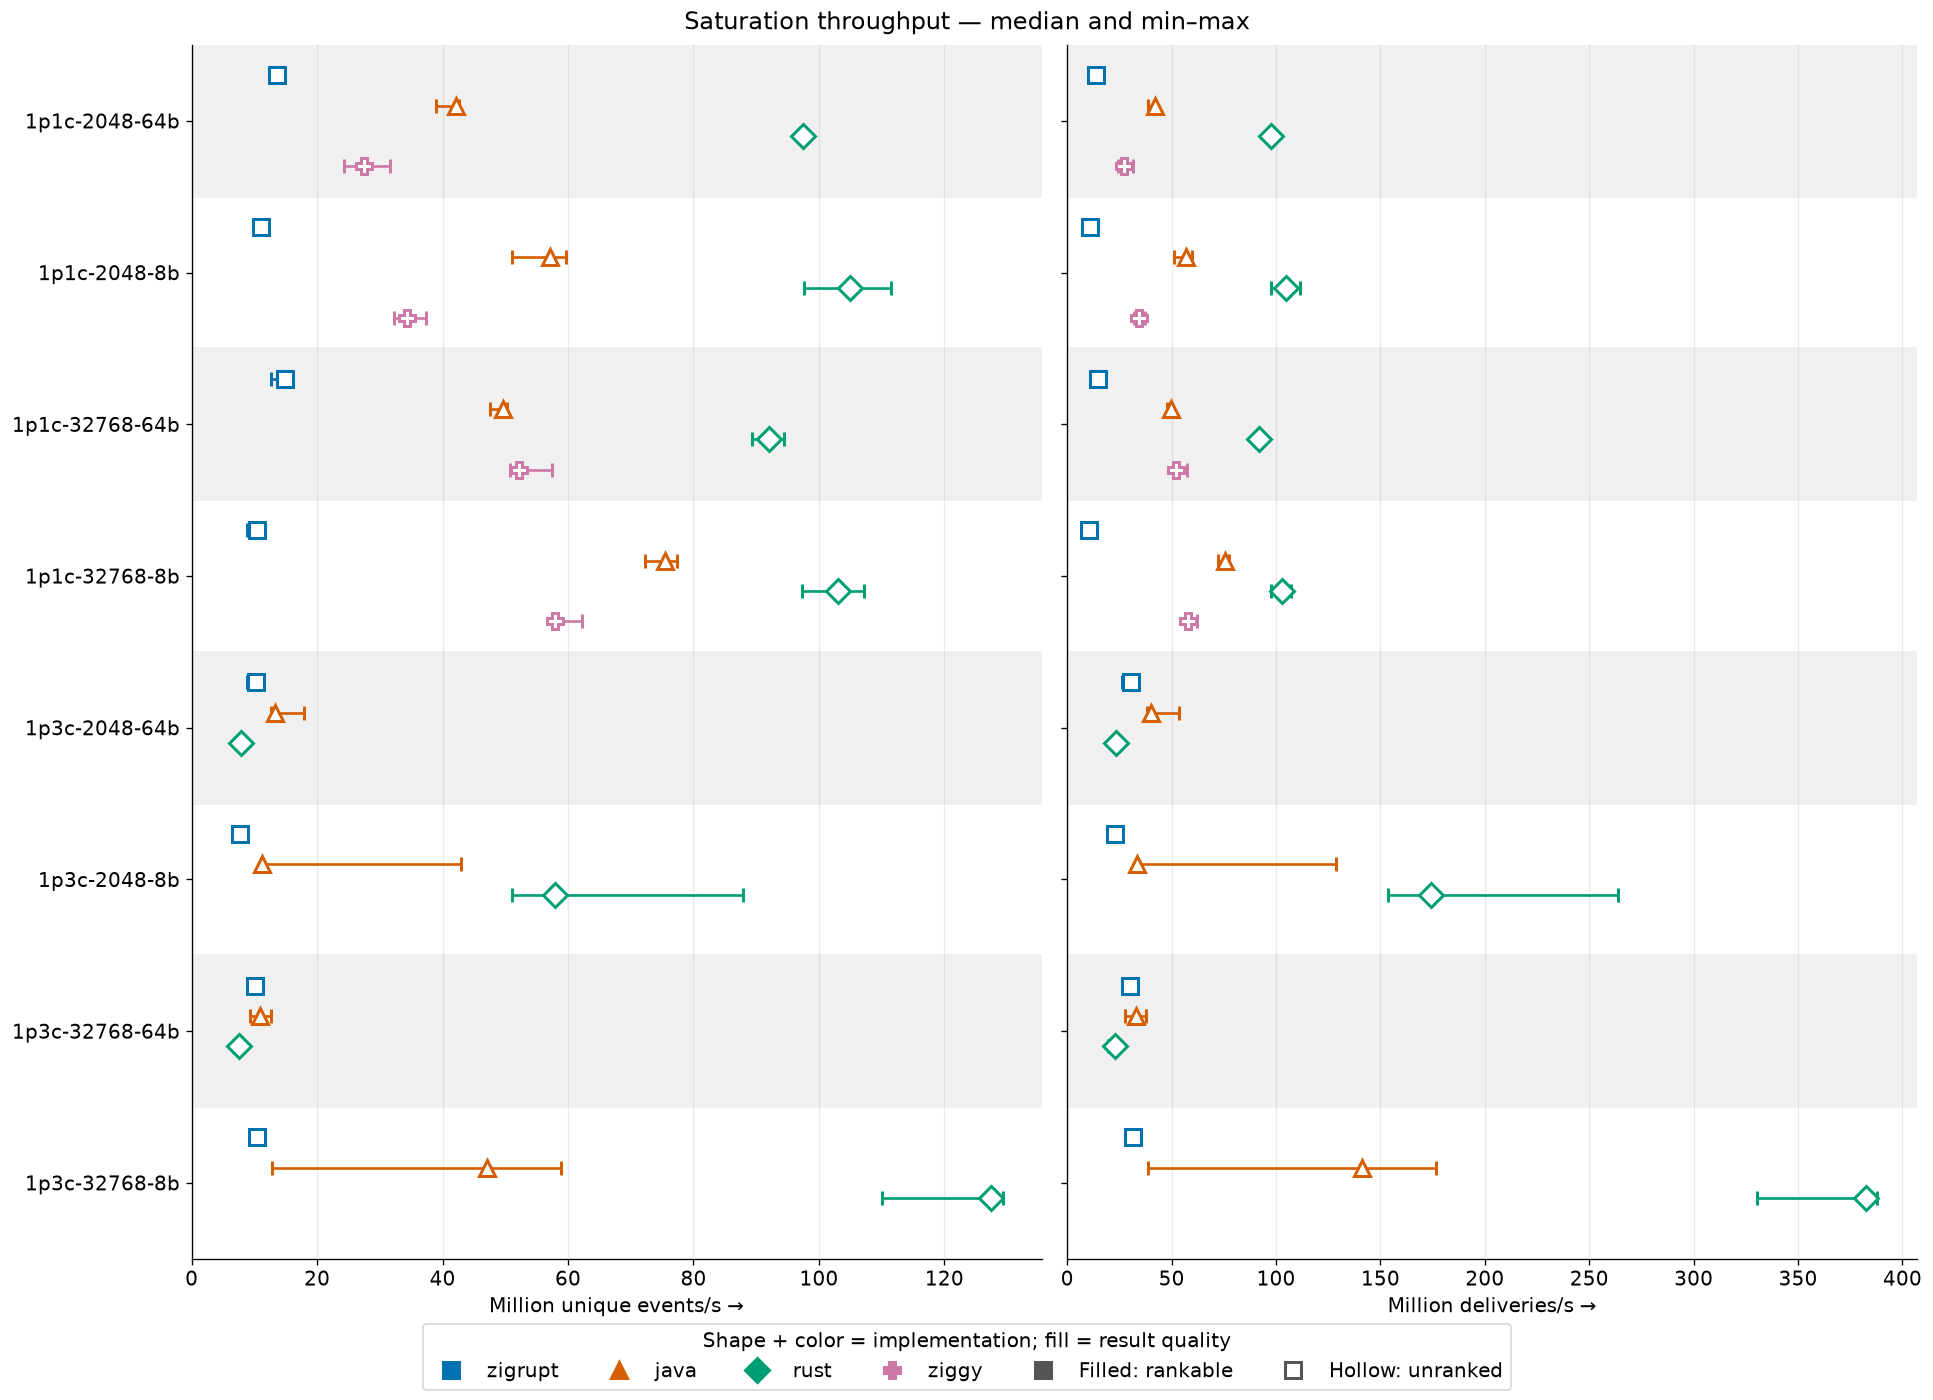

In [4]:
throughput = [row for row in rows if row["mode"] == "throughput"]
plot_metrics(throughput, [
    ("events_per_second", "Million unique events/s →", 1e6),
    ("deliveries_per_second", "Million deliveries/s →", 1e6),
], "Saturation throughput — median and min–max")


## Scheduled-arrival latency — lower is better
Read farther **left** as less delay. **p50** is the median event delay; **p99** and **p99.9** describe the slowest tail (99% and 99.9% of events fall at or below these values). Units are **microseconds (µs)**; 1,000 µs = 1 ms.

Each load is a common offered rate across implementations, derived **per workload** from the slowest median saturation throughput; 90% does not mean 90% of each implementation's capacity.

By default these are the **worst consumer per run**, then summarized across runs—not a merged histogram or the maximum of consumer medians. Set `LATENCY_CONSUMER` to inspect an individual consumer; workloads without that index have no points. Axes are linear from 0–1 µs and logarithmic above 1 µs so both tiny medians and large tails remain visible. Histogram quantiles are bucket upper bounds.

50% offered rates (unique events/s):
  1p1c-2048-64b: 6,806,284
  1p1c-2048-8b: 5,532,049
  1p1c-32768-64b: 7,452,588
  1p1c-32768-8b: 5,223,864
  1p3c-2048-64b: 3,892,956
  1p3c-2048-8b: 3,832,922
  1p3c-32768-64b: 3,779,387
  1p3c-32768-8b: 5,247,031


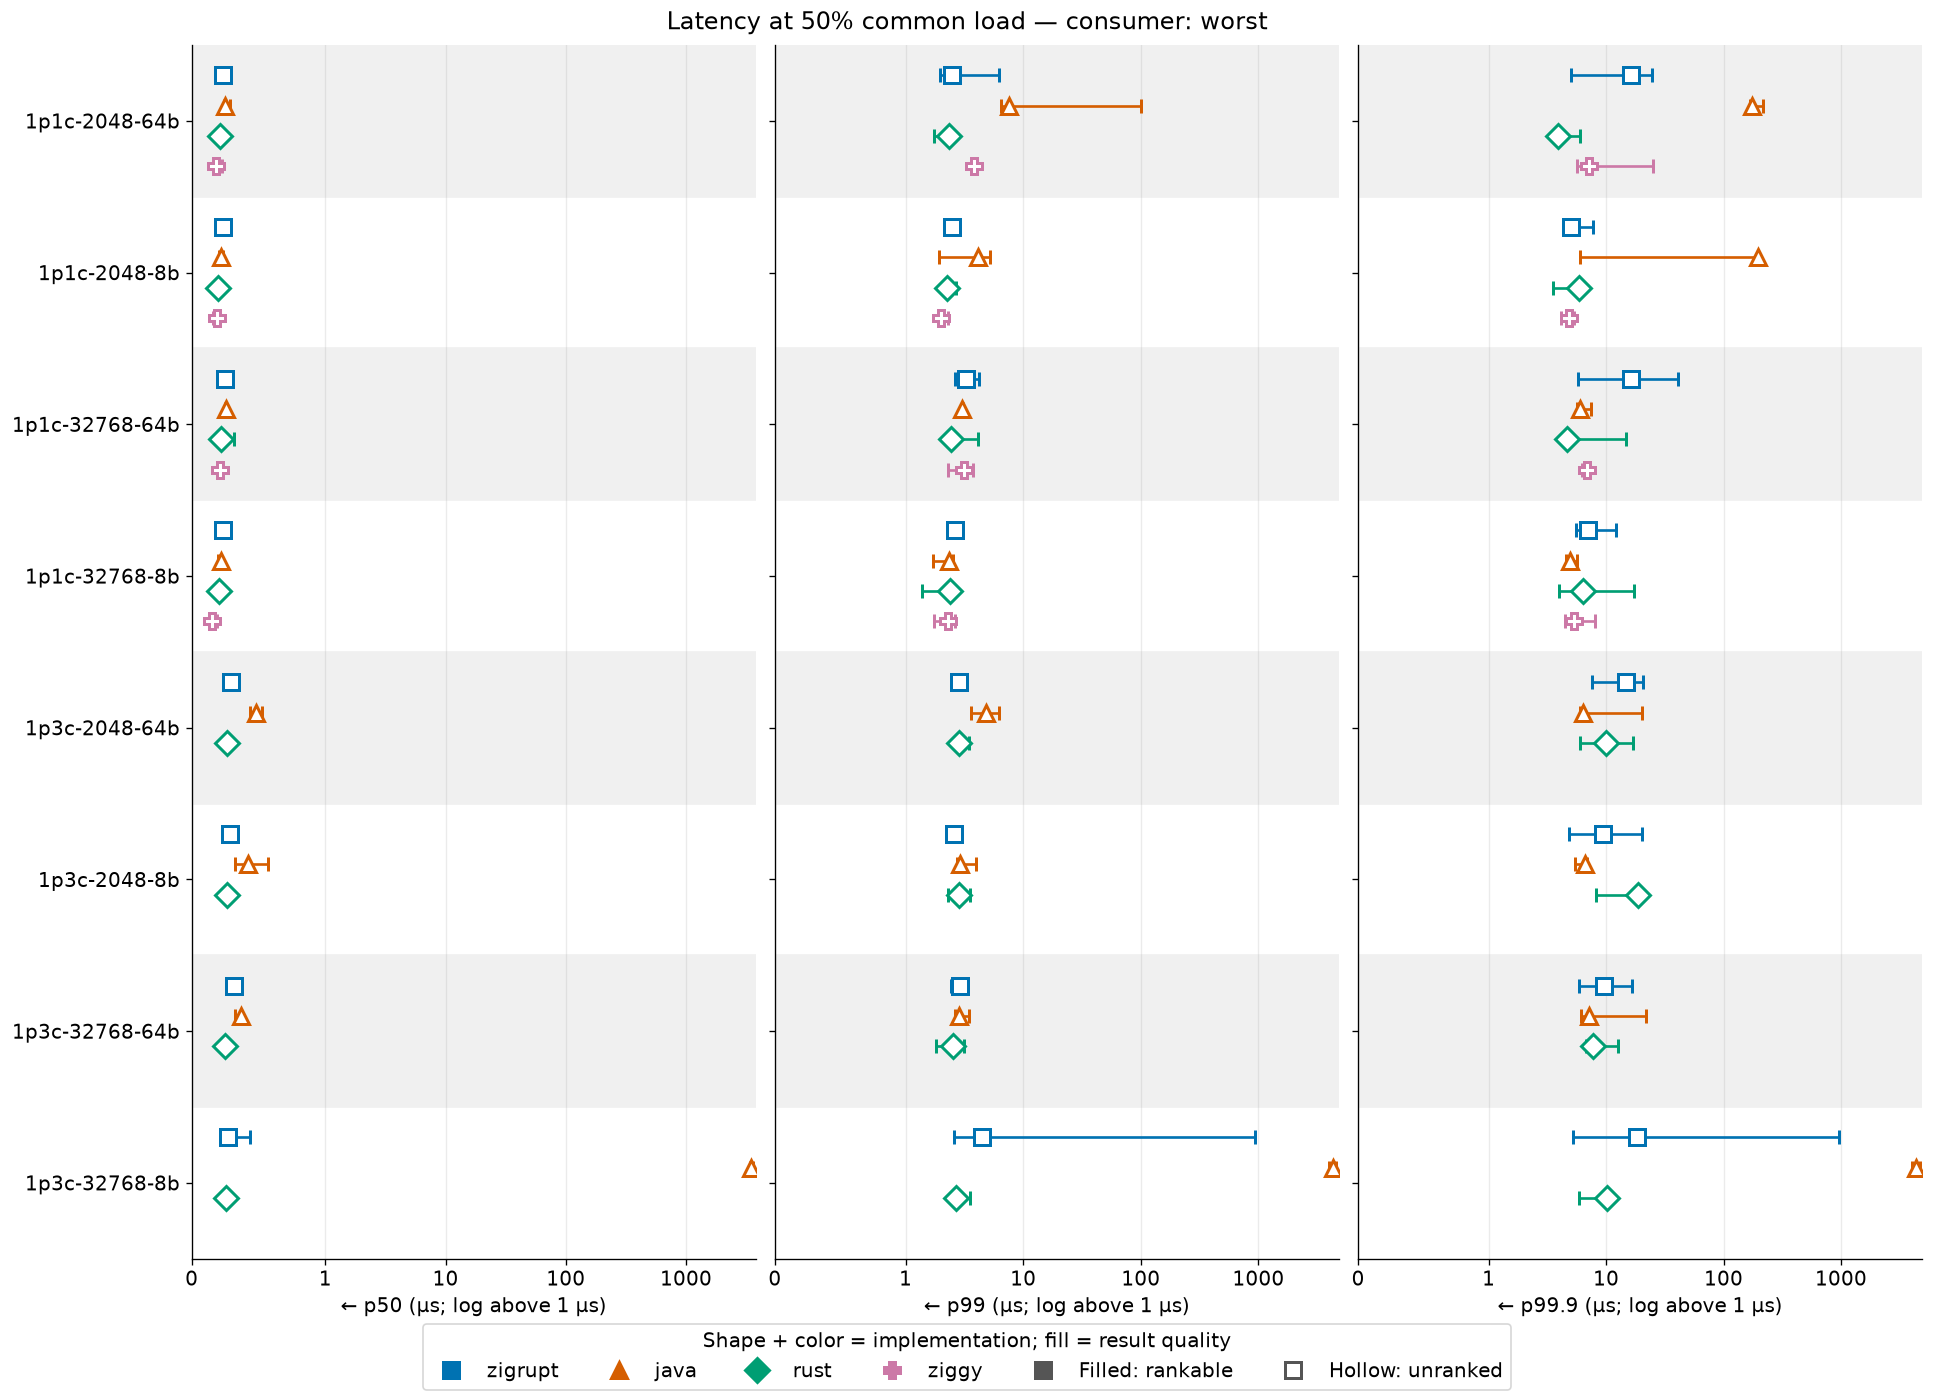

90% offered rates (unique events/s):
  1p1c-2048-64b: 12,251,312
  1p1c-2048-8b: 9,957,689
  1p1c-32768-64b: 13,414,660
  1p1c-32768-8b: 9,402,956
  1p3c-2048-64b: 7,007,322
  1p3c-2048-8b: 6,899,261
  1p3c-32768-64b: 6,802,897
  1p3c-32768-8b: 9,444,655


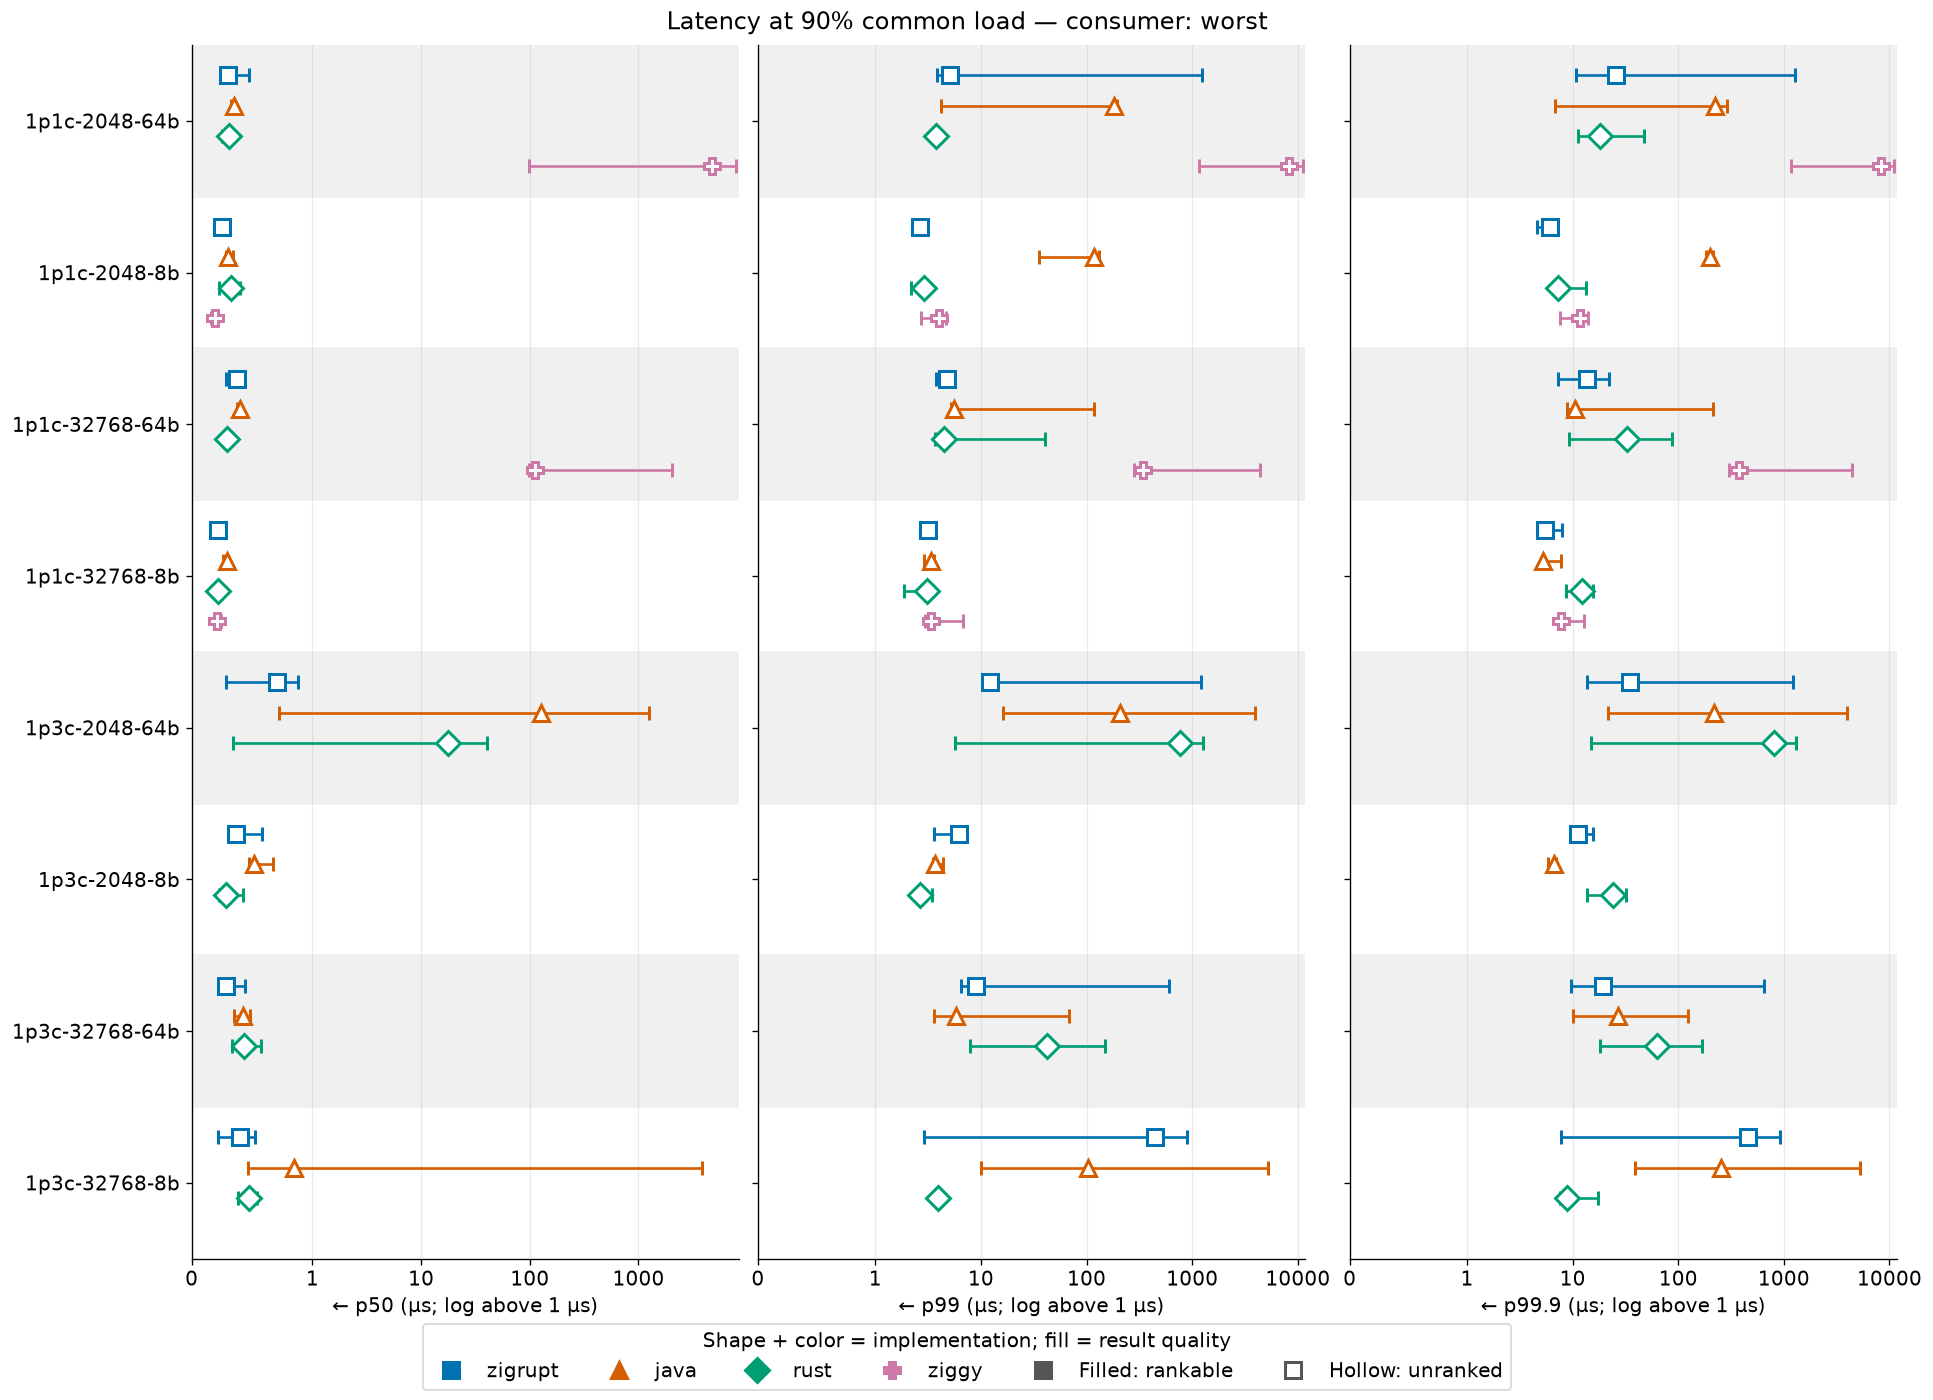

In [5]:
latency = [row for row in rows if row["mode"] == "latency"]
if not latency:
    print("No latency measurements in this selection.")
for fraction in sorted({row["fraction"] for row in latency}):
    load_rows = [row for row in latency if row["fraction"] == fraction]
    print(f"{fraction:.0%} offered rates (unique events/s):")
    for workload in sorted({row["workload"] for row in load_rows}):
        rates = sorted({row["offered_rate"] for row in load_rows if row["workload"] == workload})
        print(f"  {workload}: {', '.join(f'{rate:,.0f}' for rate in rates)}")
    plot_metrics(load_rows, [
        ("p50_ns", "← p50 (µs; log above 1 µs)", 1000),
        ("p99_ns", "← p99 (µs; log above 1 µs)", 1000),
        ("p999_ns", "← p99.9 (µs; log above 1 µs)", 1000),
    ], f"Latency at {fraction:.0%} common load — consumer: {LATENCY_CONSUMER}", log=True)


## Resource cost at saturation
CPU cores = process CPU time / measured wall time, **not CPU percentage**. Peak RSS is the process high-water mark, including startup; Java uses a fixed, pre-touched 256 MiB heap. These are costs at each implementation's own saturation throughput, not equal-work efficiency measurements. Allocation counters are omitted because their scopes differ across implementations.

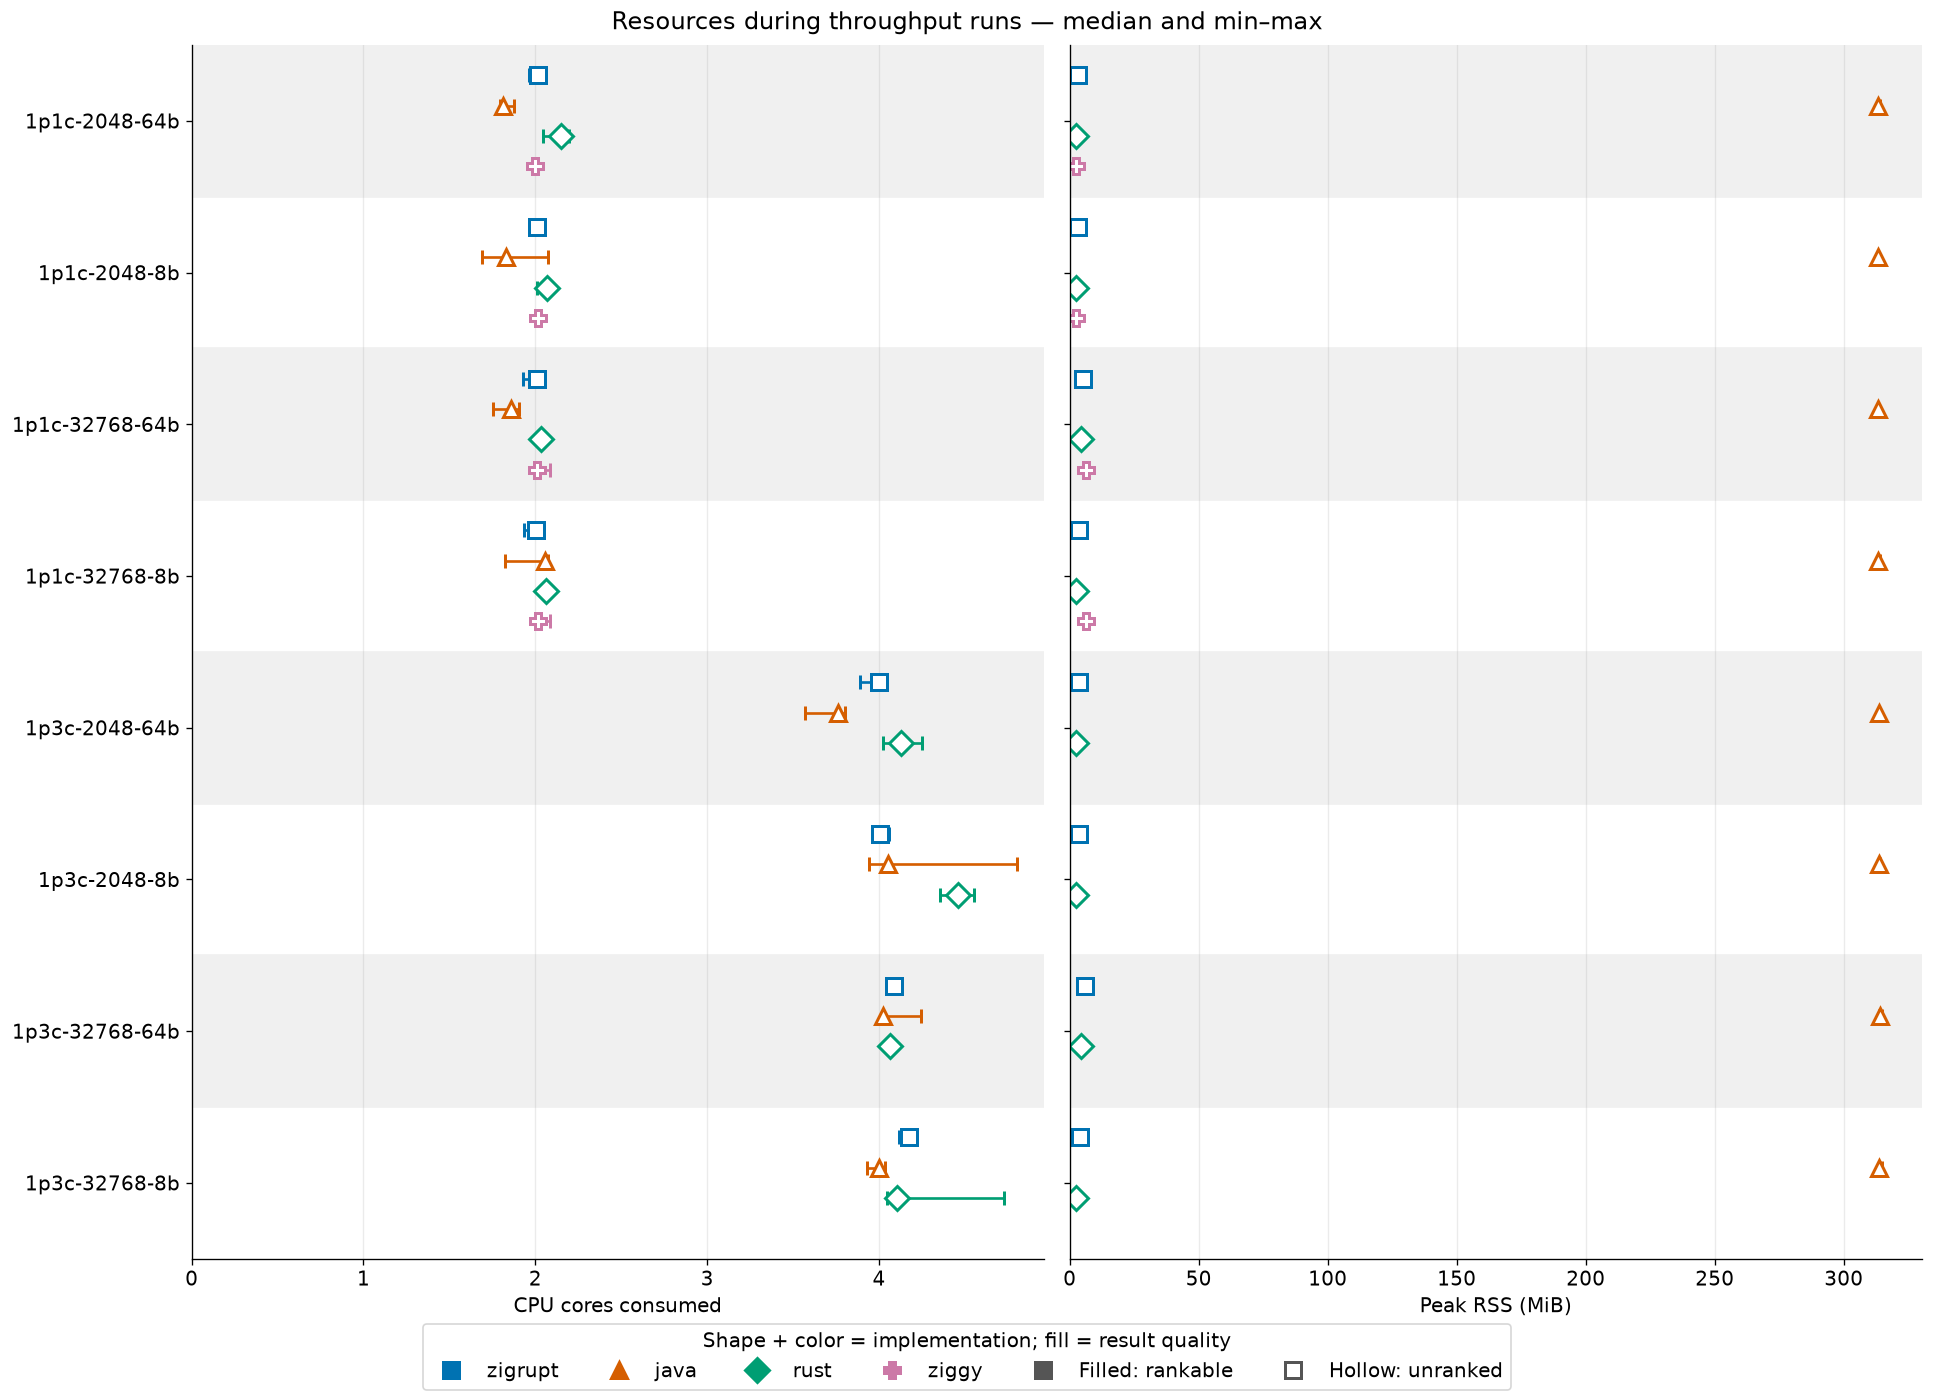

In [6]:
plot_metrics(throughput, [
    ("cpu_cores", "CPU cores consumed", 1),
    ("peak_rss_bytes", "Peak RSS (MiB)", 2**20),
], "Resources during throughput runs — median and min–max")


## Throughput repeatability — lower is more consistent
Read farther **left** as less variation between repeated runs. These markers show **CV, not medians**, and have no min–max whiskers.

Coefficient of variation = sample standard deviation / mean, shown as a percentage. Lower means more consistent repeats, not faster performance. At least two repeats are required here: the reporter's single-sample CV of zero is not evidence of stability.

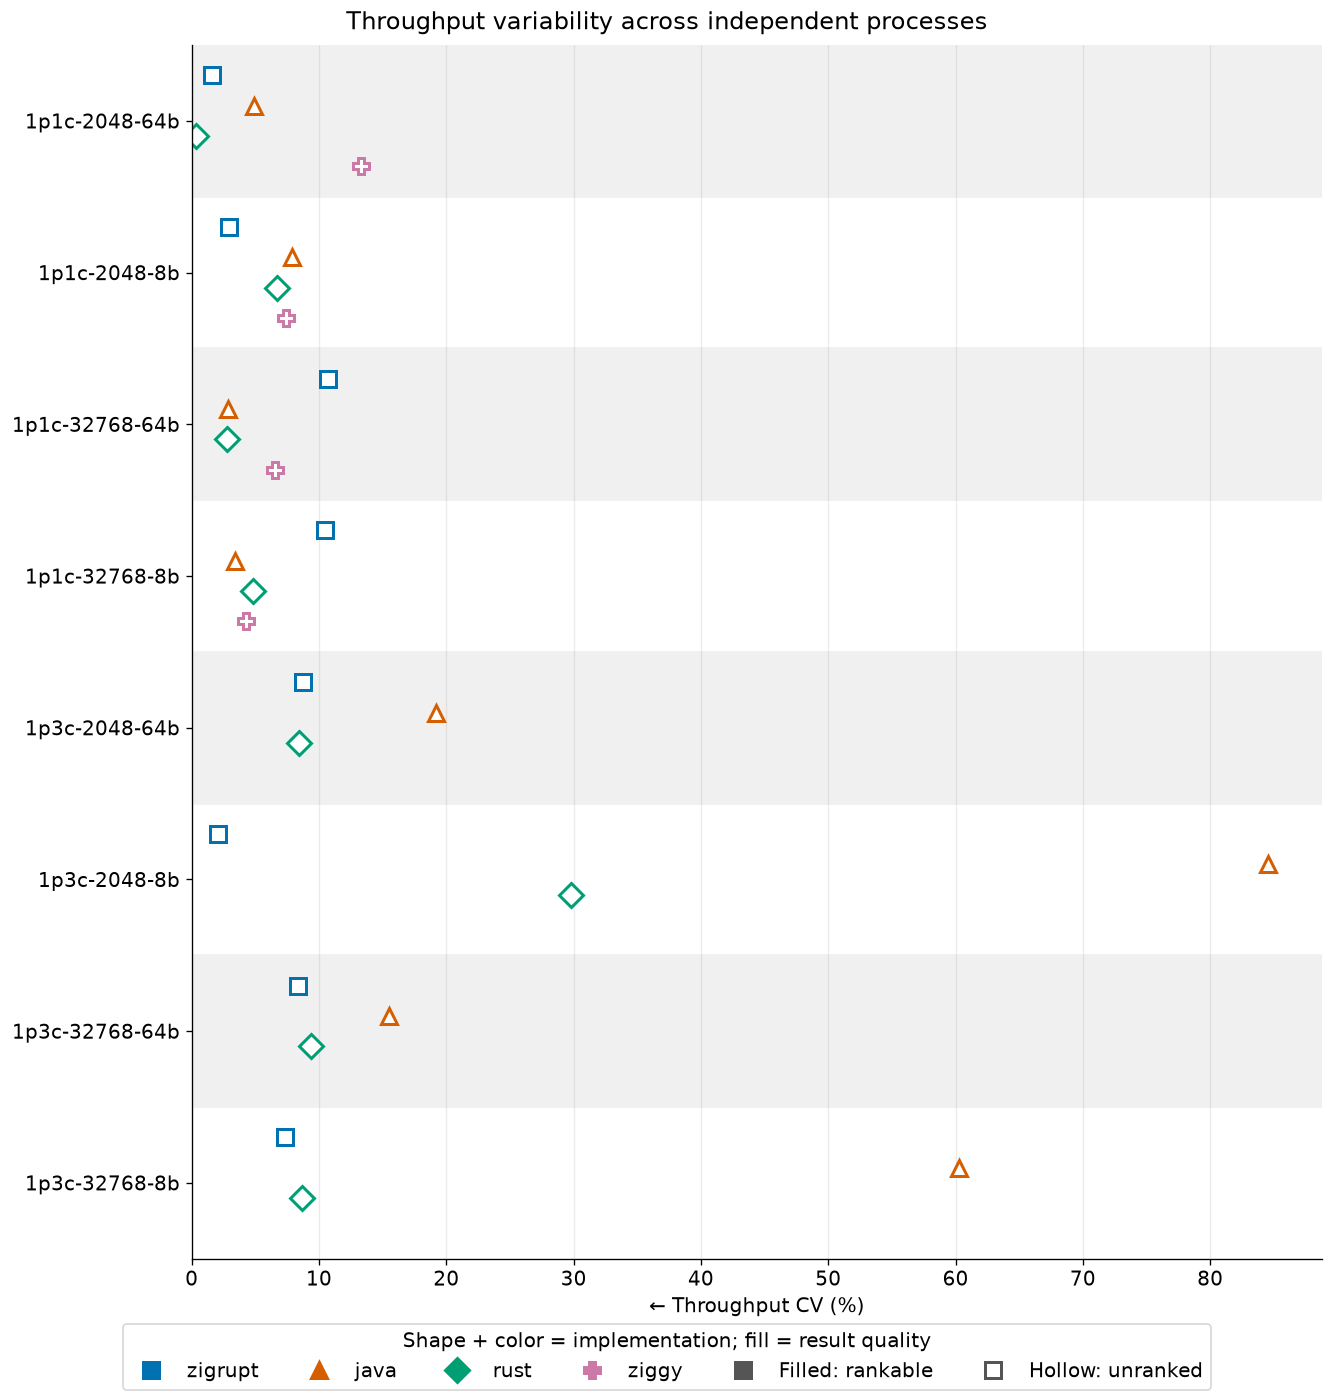

In [7]:
repeated = [row for row in throughput if row["events_per_second"]["n"] > 1]
plot_metrics(repeated, [("events_per_second", "← Throughput CV (%)", 1)],
             "Throughput variability across independent processes", variability=True)
